#### System 7 Internship
#### Week 02 
#### Day 5 
#### Regression and Scikit-learn

**Regression**

Regression is a type of supervised Machine Learning used to predict a numerical value.

Examples include:
- Predicting house prices.
- Predicting a student's final marks.
- Predicting monthly sales.
- Estimating delivery time.
Linear Regression
Linear regression uses a straight-line relationship between an input feature and a target value.

y= b<sub>0</sub> + b<sub>1</sub>x


Here, x is the input, y is the predicted value, b<sub>0</sub> is the intercept, and b<sub>1</sub> is the coefficient (slope).

Slope: 7.199999999999999
Intercept: 30.400000000000002
Predicted marks: 73.6


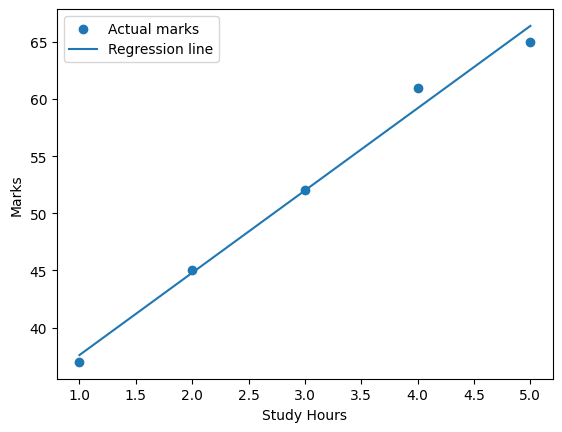

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Input feature: study hours
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

# Target: student marks
y = np.array([37, 45, 52, 61, 65])

# Create and train the model
model = LinearRegression()
model.fit(X, y)

# Predict marks for 6 study hours
prediction = model.predict([[6]])

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Predicted marks:", prediction[0])

# Visualize the data and fitted line
plt.scatter(X, y, label="Actual marks")
plt.plot(X, model.predict(X), label="Regression line")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.legend()
plt.show()

**Multiple Linear Regression**

Multiple linear regression predicts a numerical target using two or more input features.

For example, a student's marks might be predicted using study hours, attendance, and previous marks.

y=b<sub>0</sub>+b<sub>1</sub>x<sub>1</sub>+b<sub>2</sub>x<sub>2</sub>+.... +b<sub>n</sub>x<sub>bn</sub>


- x<sub>1</sub>, x<sub>2</sub>, ..., x<sub>n</sub>: input features
- b<sub>1</sub>, b<sub>2</sub>, ..., b<sub>n</sub>: learned coefficients
- b<sub>0</sub>: intercept
- y: predicted target

In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression

data = {
    "StudyHours": [1, 2, 3, 4, 5, 6],
    "Attendance": [50, 55, 60, 65, 75, 85],
    "PreviousMarks": [40, 45, 50, 55, 65, 75],
    "FinalMarks": [35, 42, 48, 55, 67, 80]
}

df = pd.DataFrame(data)

# Multiple input features
X = df[["StudyHours", "Attendance", "PreviousMarks"]]

# Target variable
y = df["FinalMarks"]

model = LinearRegression()
model.fit(X, y)

new_student = pd.DataFrame({
    "StudyHours": [5],
    "Attendance": [80],
    "PreviousMarks": [70]
})

prediction = model.predict(new_student)

print("Predicted final marks:", prediction[0])
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Predicted final marks: 73.28947368421052
Coefficients: [0.57894737 0.59736842 0.59736842]
Intercept: -19.210526315789437


**Classification vs. Regression**

Both are supervised Machine Learning tasks, but they predict different kinds of outputs.

**Regression**

Predicts a numerical value.

Examples: house price, temperature, exam marks.

Common model: LinearRegression




**Classification**

Predicts a category or class.

Examples: spam/not spam, pass/fail, low/medium/high dropout risk.

Common model: LogisticRegression



LogisticRegression is commonly used for classification.

**Scikit-learn Workflow**

Most basic Scikit-learn projects follow these steps:
1. Collect and explore data: Understand rows, features, target, missing values, and data types.
2. Prepare the data: Handle missing values, encode categories, and scale features if needed.
3. Split the dataset: Create training and test sets; use validation data or cross-validation for model selection.
4. Choose a model: For example, LinearRegression for a numerical target.
5. Train the model: Call model.fit(X_train, y_train).
6. Make predictions: Call model.predict(X_test).
7. Evaluate performance: Use suitable metrics, such as MAE or RMSE for regression.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = [[1], [2], [3], [4], [5], [6], [7], [8], [9], [10]]
y = [35, 40, 48, 52, 60, 65, 70, 78, 85, 90]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual values:", y_test)
print("Predictions:", predictions)
print("MAE:", mean_absolute_error(y_test, predictions))
print("R²:", r2_score(y_test, predictions))

Actual values: [85, 40]
Predictions: [83.49137931 41.00862069]
MAE: 1.2586206896551744
R²: 0.9967474053522408


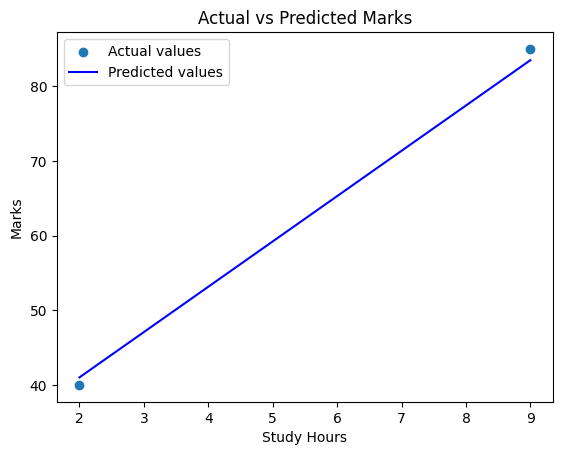

In [7]:
plt.scatter(X_test,y_test, label='Actual values')
plt.plot(X_test, predictions, color='blue', label='Predicted values')
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.show()

**Metrics:**

- MAE (Mean Absolute Error): The average absolute difference between actual and predicted values. Lower is generally better.
- R² score: Measures how well the model explains variation in the target compared with predicting its mean. A value closer to 1 is generally better, but it can be negative on test data.

### Practice Task

In [10]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

data = {
    "Study_Hours": [2, 4, 3, 6, 5, 7, 1, 8, 4, 6, 3, 9, 5, 2, 7],
    "Attendance": [60, 75, 70, 90, 85, 95, 50, 98, 80, 88, 65, 99, 82, 55, 92],
    "Assignment_Marks": [10, 15, 12, 18, 17, 19, 8, 20, 16, 18, 11, 20, 17, 9, 19],
    "Final_Marks": [35, 55, 45, 78, 70, 88, 25, 95, 65, 80, 40, 98, 72, 30, 90]
}

df = pd.DataFrame(data)

df.head()

,Study_Hours,Attendance,Assignment_Marks,Final_Marks
0,2,60,10,35
1,4,75,15,55
2,3,70,12,45
3,6,90,18,78
4,5,85,17,70


In [11]:
X = df[["Study_Hours", "Attendance", "Assignment_Marks"]]
y = df["Final_Marks"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)
print("predictions:", y_pred)

Mean Absolute Error: 1.6765317884462831
R² Score: 0.9949997694101843
predictions: [ 79.26914268 100.76449454  33.4657565 ]


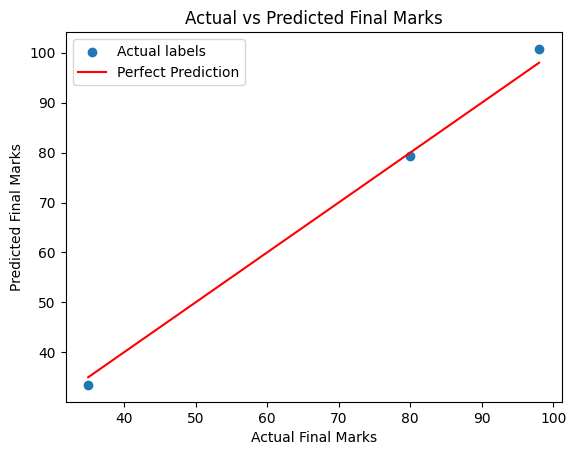

In [12]:
plt.scatter(y_test, y_pred, label='Actual labels')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label='Perfect Prediction')
plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Final Marks")
plt.legend() 
plt.show()